# Topic: Who publishes datasets
## QUESTION: Which UCSD research fields/sources produce the datasets that show up in OpenAlex, and how has that changed from 2020 to 2026?

Relevant Tables/Fields:
- works table
- fields: type, year, source, field, domain, open access status, funder, MAYBE citation count

#### Subquestions:
1. How many datasets are there per year, and what share of all works?
2. Which sources hold them, and does one or two dominate?
3. Which fields and domains do they come from?

In [ ]:
# Looking at stats
import pandas as pd
w = pd.read_csv("data/tables/works.csv", keep_default_na=False, na_values=[""])
d = w[w["Type"] == "dataset"]
print(len(d), f"{len(d) / len(w):.1%} of all works")
print(d["Source"].value_counts().head(10))
print(d["Field"].value_counts().head(10))
print(d.groupby("Year").size())

20530 15.6% of all works
Source
UC San Diego                                                                           12522
The Human BioMolecular Atlas Program (HuBMAP)                                           3215
DOE Pacific Northwest National Laboratory (PNNL) Repository                             1054
OSTI OAI (U.S. Department of Energy Office of Scientific and Technical Information)      949
IUPAC Standards Online                                                                   707
Zenodo (CERN European Organization for Nuclear Research)                                 606
Cellular Senescence Network (SenNet)                                                     459
ENCODE Datasets                                                                          234
Harvard Dataverse                                                                        219
Figshare                                                                                 129
Name: count, dtype: int64
Field
Bioche

In [2]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

DATASET_TYPES = ["dataset"]       # OpenAlex types counted as datasets
TOP_N = 10                        # rows in the top-N tables and charts
SOURCES_IN_CHART = 4              # sources drawn in the by-year chart; the rest are grouped as "Other"
LAST_YEAR_IS_PARTIAL = True       # the newest year in the data is not finished yet
NO_SOURCE = "(no source listed)"  # label for works without a source


def find_tables_dir():
    here = Path.cwd()
    for base in [here, here.parent, here.parent.parent]:
        candidate = base / "data" / "tables"
        if (candidate / "works.csv").exists():
            return candidate
    raise FileNotFoundError("Could not find data/tables/works.csv. Run convert_export.py first, "
                            "and open this notebook from the repo folder.")


TABLES_DIR = find_tables_dir()
OUTPUT_DIR = TABLES_DIR.parent.parent / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_OUT_DIR = OUTPUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Reading tables from:", TABLES_DIR)

Reading tables from: /Users/aurora/Desktop/lib-research/lib-hdsi-2026-research-analytics/data/tables


In [ ]:
# Helper functions for charts and tables
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["axes.unicode_minus"] = False


def compact(value, pos=None):
    if value >= 1_000_000:
        return f"{value / 1_000_000:g}M"
    if value >= 10_000:
        return f"{value / 1_000:g}K"
    return f"{value:,.0f}"


def shorten(text, n=42):
    return text if len(text) <= n else text[: n - 1] + "\u2026"


def style_ax(ax, grid_axis):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(length=0, colors=MUTED, labelsize=9)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def set_titles(ax, title, subtitle=""):
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", color=INK, pad=30)
    if subtitle:
        ax.text(0, 1.035, subtitle, transform=ax.transAxes, fontsize=9, color=INK2, va="bottom")


def new_fig(ncols=1, width=9.0, height=4.6):
    fig, axes = plt.subplots(1, ncols, figsize=(width, height))
    fig.patch.set_facecolor(SURFACE)
    return fig, axes


def draw_columns(ax, labels, values, number_format="{:,.0f}", compact_axis=True):
    x = list(range(len(labels)))
    top = max(values) if len(values) else 1
    ax.bar(x, values, width=0.34, color=SERIES[0], zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0, top * 1.14)
    for xi, v in zip(x, values):
        ax.text(xi, v + top * 0.015, number_format.format(v), ha="center", va="bottom", fontsize=9, color=INK2)
    if compact_axis:
        ax.yaxis.set_major_formatter(FuncFormatter(compact))
    style_ax(ax, "y")


def draw_hbars(ax, labels, values, number_format="{:,.0f}"):
    y = list(range(len(labels)))[::-1]
    top = max(values) if len(values) else 1
    ax.barh(y, values, height=0.55, color=SERIES[0], zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels([shorten(str(label)) for label in labels])
    ax.set_xlim(0, top * 1.16)
    for yi, v in zip(y, values):
        ax.text(v + top * 0.012, yi, number_format.format(v), va="center", fontsize=9, color=INK2)
    ax.xaxis.set_major_formatter(FuncFormatter(compact))
    style_ax(ax, "x")


def draw_stacked(ax, table, colors, percent=False):
    x = list(range(len(table)))
    bottoms = [0] * len(table)
    for col in table.columns:
        vals = [float(v) for v in table[col].values]
        ax.bar(x, vals, bottom=bottoms, width=0.34, color=colors[col], edgecolor=SURFACE, linewidth=1.5, label=col, zorder=3)
        bottoms = [b + v for b, v in zip(bottoms, vals)]
    ax.set_xticks(x)
    ax.set_xticklabels([str(i) for i in table.index])
    if percent:
        ax.set_ylim(0, 100)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
    else:
        ax.yaxis.set_major_formatter(FuncFormatter(compact))
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=len(table.columns),
              fontsize=9, labelcolor=INK2, handlelength=1, handleheight=1, columnspacing=1.6)
    style_ax(ax, "y")


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, facecolor=SURFACE, bbox_inches="tight")
    plt.show()


def save_table(df, name):
    df.to_csv(TABLE_OUT_DIR / f"{name}.csv", index=False)


def show(df):
    out = df.copy()
    for col in out.columns:
        if col == "Year":
            continue
        if pd.api.types.is_integer_dtype(out[col]):
            out[col] = out[col].map(lambda v: "" if pd.isna(v) else f"{v:,}")
        elif pd.api.types.is_float_dtype(out[col]):
            out[col] = out[col].map(lambda v: "" if pd.isna(v) else f"{v:,.2f}")
    display(out.reset_index(drop=True))

In [4]:
def read_table(name, **kwargs):
    return pd.read_csv(TABLES_DIR / f"{name}.csv", keep_default_na=False, na_values=[""], **kwargs)


works = read_table("works", dtype={"Work ID": str, "DOI": str, "Source IDs": str})
works["Year"] = pd.to_numeric(works["Year"], errors="coerce").astype("Int64")
works["Citation count"] = pd.to_numeric(works["Citation count"], errors="coerce").fillna(0).astype(int)
works["Source"] = works["Source"].fillna(NO_SOURCE)
funders = read_table("work_funders", dtype={"Work ID": str, "Funder": str, "Funder ID": str})

datasets = works[works["Type"].isin(DATASET_TYPES)].copy()
last_year = int(works["Year"].max())


def year_label(y):
    return f"{y}*" if (LAST_YEAR_IS_PARTIAL and y == last_year) else str(y)


print(f"{len(works):,} works in total; {len(datasets):,} are datasets ({len(datasets) / len(works):.1%})")

131,927 works in total; 20,530 are datasets (15.6%)


##### DATASETS BY YEAR

,Year,Datasets,All works,Share of all works (%)
0,2020,"5,068","20,354",24.90
1,2021,"3,242","18,001",18.00
2,2022,"2,758","17,443",15.80
3,2023,"3,315","18,014",18.40
4,2024,"1,318","18,165",7.30
5,2025,629,"18,503",3.40
6,2026,"4,200","21,447",19.60


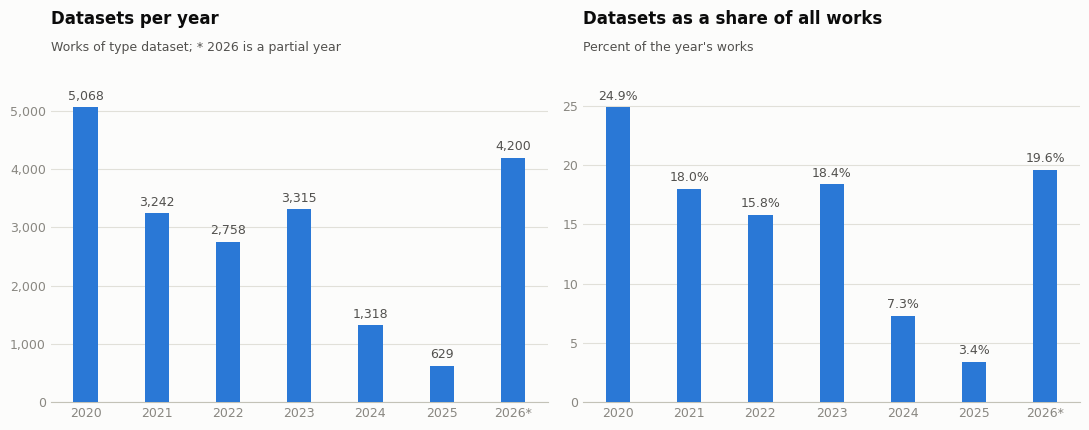

In [5]:
per_year = works.assign(Is_dataset=works["Type"].isin(DATASET_TYPES)).groupby("Year").agg(
    Datasets=("Is_dataset", "sum"),
    All_works=("Work ID", "size"),
).reset_index()
per_year["Share of all works (%)"] = (per_year["Datasets"] / per_year["All_works"] * 100).round(1)
per_year = per_year.rename(columns={"All_works": "All works"})
show(per_year)
save_table(per_year, "datasets_per_year")

labels = [year_label(int(y)) for y in per_year["Year"]]
fig, (ax1, ax2) = new_fig(ncols=2, width=11, height=4.4)
draw_columns(ax1, labels, [int(v) for v in per_year["Datasets"]])
set_titles(ax1, "Datasets per year", "Works of type dataset" + (f"; * {last_year} is a partial year" if LAST_YEAR_IS_PARTIAL else ""))
draw_columns(ax2, labels, [float(v) for v in per_year["Share of all works (%)"]], number_format="{:.1f}%", compact_axis=False)
set_titles(ax2, "Datasets as a share of all works", "Percent of the year's works")
finish(fig, "datasets_per_year")

##### TOP REPOSITORIES/SOURCES

Datasets come from 71 different repositories
  Top  1 repositories hold 61% of all datasets
  Top  3 repositories hold 82% of all datasets
  Top  5 repositories hold 90% of all datasets
  Top 10 repositories hold 98% of all datasets


,Repository,Datasets,Share of datasets (%),Cumulative share (%)
0,UC San Diego,"12,522",61.00,61.00
1,The Human BioMolecular Atlas Program (HuBMAP),"3,215",15.70,76.70
2,DOE Pacific Northwest National Laboratory (PNN...,"1,054",5.10,81.80
3,OSTI OAI (U.S. Department of Energy Office of ...,949,4.60,86.40
4,IUPAC Standards Online,707,3.40,89.80
5,Zenodo (CERN European Organization for Nuclear...,606,3.00,92.80
6,Cellular Senescence Network (SenNet),459,2.20,95.00
7,ENCODE Datasets,234,1.10,96.10
8,Harvard Dataverse,219,1.10,97.20
9,Figshare,129,0.60,97.80


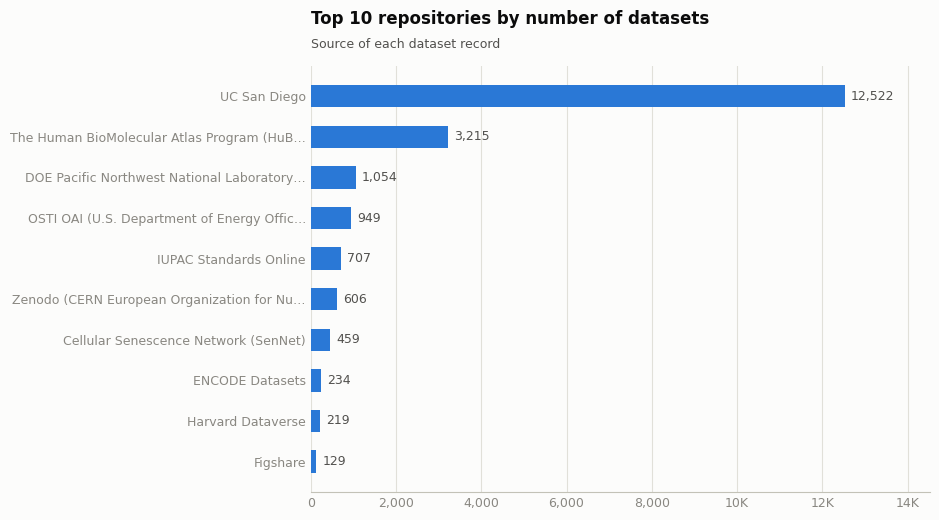

In [6]:
source_counts = datasets["Source"].value_counts().rename_axis("Repository").rename("Datasets").reset_index()
source_counts["Share of datasets (%)"] = (source_counts["Datasets"] / len(datasets) * 100).round(1)
source_counts["Cumulative share (%)"] = source_counts["Share of datasets (%)"].cumsum().round(1)

print(f"Datasets come from {len(source_counts):,} different repositories")
for k in (1, 3, 5, 10):
    share = source_counts["Datasets"].head(k).sum() / len(datasets)
    print(f"  Top {k:>2} repositories hold {share:.0%} of all datasets")

top_sources = source_counts.head(TOP_N)
show(top_sources)
save_table(top_sources, "datasets_top_repositories")

fig, ax = new_fig(width=9.5, height=0.34 * len(top_sources) + 1.9)
draw_hbars(ax, list(top_sources["Repository"]), list(top_sources["Datasets"]))
set_titles(ax, f"Top {len(top_sources)} repositories by number of datasets", "Source of each dataset record")
finish(fig, "datasets_top_repositories")

##### Sources by year

Group,Year,UC San Diego,The Human BioMolecular Atlas Program (HuBMAP),DOE Pacific Northwest National Laboratory (PNNL) Repository,OSTI OAI (U.S. Department of Energy Office of Scientific and Technical Information),Other
0,2020,"4,586",0,114,205,163
1,2021,"2,915",0,117,51,159
2,2022,"2,113",0,207,25,413
3,2023,"1,869",0,219,293,934
4,2024,768,0,153,375,22
5,2025,48,22,244,0,315
6,2026,223,"3,193",0,0,784


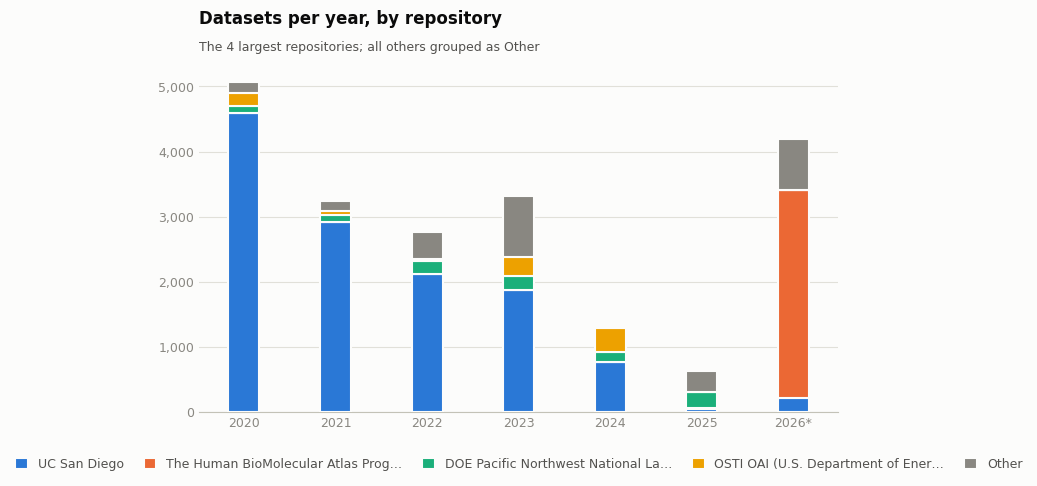

In [7]:
chart_sources = list(source_counts["Repository"].head(SOURCES_IN_CHART))
SOURCE_COLORS = {name: SERIES[i] for i, name in enumerate(chart_sources)}
SOURCE_COLORS["Other"] = MUTED

by_year_source = (
    datasets.assign(Group=datasets["Source"].where(datasets["Source"].isin(chart_sources), "Other"))
    .groupby(["Year", "Group"]).size().unstack("Group", fill_value=0)
    .reindex(columns=chart_sources + ["Other"], fill_value=0)
)
table = by_year_source.rename_axis("Year").reset_index()
show(table)
save_table(table, "datasets_repositories_per_year")

by_year_source.index = [year_label(int(y)) for y in by_year_source.index]
fig, ax = new_fig(width=9.5, height=5.0)
draw_stacked(ax, by_year_source.rename(columns=lambda c: shorten(c, 34)),
             {shorten(k, 34): v for k, v in SOURCE_COLORS.items()})
set_titles(ax, "Datasets per year, by repository", f"The {SOURCES_IN_CHART} largest repositories; all others grouped as Other")
finish(fig, "datasets_repositories_per_year")

##### Sample titles from biggest sources

In [8]:
samples = []
for name in source_counts["Repository"].head(5):
    part = datasets[datasets["Source"] == name]
    samples.append(part.sample(min(3, len(part)), random_state=1)[["Source", "Year", "Title"]])
sample_titles = pd.concat(samples)
pd.set_option("display.max_colwidth", 120)
display(sample_titles.reset_index(drop=True))
save_table(sample_titles, "datasets_sample_titles")

,Source,Year,Title
0,UC San Diego,2020,BindingDB Entry 50003072: Design of Y
1,UC San Diego,2026,MassIVE MSV000102013 - SMIRC marine metabolomes 2024-2025 San Diego
2,UC San Diego,2020,BindingDB Entry 50005423: Identification and synthesis of N-(thiophen-2-yl) benzamide derivatives as BRAF(V600E) inh...
3,The Human BioMolecular Atlas Program (HuBMAP),2026,GeoMx (NGS) data from the placenta of a 25-year-old white female
4,The Human BioMolecular Atlas Program (HuBMAP),2026,Auto-fluorescence data from the lung (right) of a 19.99-year-old black or african american male
5,The Human BioMolecular Atlas Program (HuBMAP),2026,GeoMx (NGS) data from the placenta of a 31-year-old white female
6,DOE Pacific Northwest National Laboratory (PNNL) Repository,2024,Data for EMSL Project 50414 from November 2024
7,DOE Pacific Northwest National Laboratory (PNNL) Repository,2025,Data for EMSL Project 50414 from February 2025
8,DOE Pacific Northwest National Laboratory (PNNL) Repository,2022,Data for EMSL Project 50414 from July 2022
9,OSTI OAI (U.S. Department of Energy Office of Scientific and Technical Information),2023,Data for EMSL Project 48135 from February 2023


##### Fields and domains

,Field,Datasets,Share of datasets (%)
0,"Biochemistry, Genetics and Molecular Biology","8,276",40.30
1,Medicine,"3,285",16.00
2,Chemistry,"2,906",14.20
3,(no field),"2,055",10.00
4,"Pharmacology, Toxicology and Pharmaceutics","1,544",7.50
5,Neuroscience,800,3.90
6,Immunology and Microbiology,542,2.60
7,Earth and Planetary Sciences,258,1.30
8,Agricultural and Biological Sciences,160,0.80
9,Physics and Astronomy,154,0.80


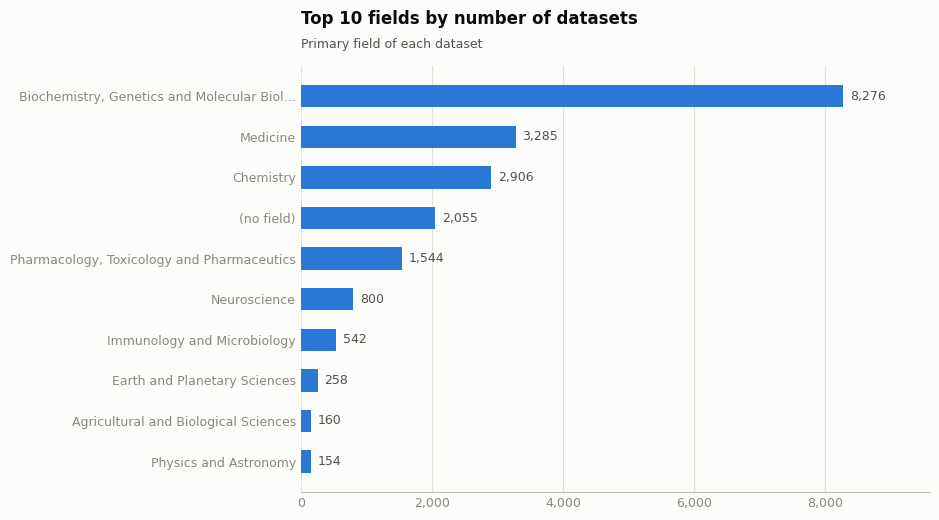

,Domain,Datasets,Share of datasets (%)
0,Life Sciences,"11,322",55.10
1,Physical Sciences,"3,592",17.50
2,Health Sciences,"3,306",16.10
3,(no domain),"2,055",10.00
4,Social Sciences,255,1.20


In [9]:
field_counts = datasets["Field"].fillna("(no field)").value_counts().rename_axis("Field").rename("Datasets").reset_index()
field_counts["Share of datasets (%)"] = (field_counts["Datasets"] / len(datasets) * 100).round(1)
top_fields = field_counts.head(TOP_N)
show(top_fields)
save_table(top_fields, "datasets_top_fields")

fig, ax = new_fig(width=9.5, height=0.34 * len(top_fields) + 1.9)
draw_hbars(ax, list(top_fields["Field"]), list(top_fields["Datasets"]))
set_titles(ax, f"Top {len(top_fields)} fields by number of datasets", "Primary field of each dataset")
finish(fig, "datasets_top_fields")

domain_counts = datasets["Domain"].fillna("(no domain)").value_counts().rename_axis("Domain").rename("Datasets").reset_index()
domain_counts["Share of datasets (%)"] = (domain_counts["Datasets"] / len(datasets) * 100).round(1)
show(domain_counts)
save_table(domain_counts, "datasets_domains")

In [ ]:
# which sources/repositories supply each field
fields5 = list(top_fields["Field"].head(5))
cross = (
    datasets.assign(
        Field=datasets["Field"].fillna("(no field)"),
        Repository=datasets["Source"].where(datasets["Source"].isin(chart_sources), "Other"),
    )
    .query("Field in @fields5")
    .groupby(["Field", "Repository"]).size().unstack("Repository", fill_value=0)
    .reindex(columns=chart_sources + ["Other"], fill_value=0)
    .reindex(fields5)
)
show(cross.reset_index())
save_table(cross.reset_index(), "datasets_fields_by_repository")

Repository,Field,UC San Diego,The Human BioMolecular Atlas Program (HuBMAP),DOE Pacific Northwest National Laboratory (PNNL) Repository,OSTI OAI (U.S. Department of Energy Office of Scientific and Technical Information),Other
0,"Biochemistry, Genetics and Molecular Biology","4,168","3,213",0,0,895
1,Medicine,"3,164",2,0,0,119
2,Chemistry,"2,189",0,0,0,717
3,(no field),28,0,"1,054",949,24
4,"Pharmacology, Toxicology and Pharmaceutics","1,530",0,0,0,14
